[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/NavigatorPrime/CNN-Image-Classifier/blob/EN3150-A03-Final-Corrected-Report/Draco_A03_EN3150.ipynb)

# EN3150: Pattern Recognition — Assignment 03
## Resource-Constrained CNN for Edge Image Classification
### DeFungi 64×64 Benchmark & Lightweight Architecture Evaluation

---

**University:** University of Moratuwa  
**Department:** Department of Electronic and Telecommunication Engineering  
**Instructor:** Dr. Sampath K. Perera  
**Academic Term:** October 2026  

### Group: **Draco** (*"Dealing with AI from the core"*)

| Student Name | Registration / Index No. | Role / Focus |
| :--- | :---: | :--- |
| **GUNARATHNA K.T.M.B.** | `230203G` | Model B Architecture & MAC Analysis |
| **JAYAWARDANA K.P.P.** | `230294H` | Model A Baseline & Hardware Justifications |
| **JITHMAL P.G.I.** | `230306B` | Task 3 Optimizer Convergence & Tuning |
| **NIMADITH W.N.A.C.** | `230442L` | Task 5 SOTA Transfer Learning & Multi-Model Trade-offs |

**GitHub Repository:** [https://github.com/NavigatorPrime/CNN-Image-Classifier](https://github.com/NavigatorPrime/CNN-Image-Classifier)  
**Authoritative Branch:** `EN3150-A03-Final-Corrected-Report`  
**Official Report Document:** `reports/Draco_A03_EN3150.pdf`  

---

### Executive Overview & Rubric Roadmap
This Jupyter Notebook provides a complete, reproducible, and self-contained implementation of all six tasks mandated by the EN3150 Assignment 03 rubric:
1. **Task 1: Data Preparation & Integrity Audit** — Deterministic 70/15/15 class-aware split on UCI DeFungi ($64\times 64$ RGB, 5 classes), with cryptographic verification of 0 cross-split duplicate leakage.
2. **Task 2: Custom Architecture Design & Hardware Justifications [20 Marks]** — Design and layer-by-layer parameter calculation for **Model A** (Standard CNN) and **Model B** (Lightweight Depthwise Separable CNN, strictly constrained to $\le 100{,}000$ trainable parameters).
3. **Task 3: Optimizer Selection, Tuning & Convergence Analysis [15 Marks]** — Controlled comparison of **Adam** ($lr=0.001$), **Standard SGD** ($lr=0.01$), and **SGD + Momentum** ($lr=0.01, \gamma=0.9$) under identical initial weights, loss, and data splits.
4. **Task 4: Custom Model Training & Evaluation [25 Marks]** — 20-epoch training and hold-out test evaluation of Models A and B (Accuracy, Loss, Confusion Matrices, Precision, Recall, F1, MACs/FLOPs, and disk footprint).
5. **Task 5: Lightweight SOTA Fine-Tuning & Evaluation [20 Marks]** — Transfer learning with **MobileNetV2** and **ShuffleNetV2 1.0x** using identical splits, evaluating test performance, parameter counts, and model sizes (MB).
6. **Task 6: Final Comparison & Architectural Trade-off Discussion [20 Marks]** — Multi-dimensional analysis (Accuracy vs. Memory Footprint vs. Computational Cost) comparing custom edge CNNs against pre-trained SOTA models.


---
## Section 0: Environment Setup, Configuration & Deterministic Seeding

To ensure complete scientific reproducibility, random number generators across Python, NumPy, and PyTorch (CPU and CUDA) are deterministically locked with seed `42`.

> **Note on Execution Modes:**
> - `TRAIN_FROM_SCRATCH = False` (Default): Instantly loads canonical, leakage-free trained checkpoints from `results_clean_split/`, executing full test-set evaluations, confusion matrices, and metrics in seconds without requiring hours of GPU/CPU compute.
> - `TRAIN_FROM_SCRATCH = True`: Re-trains all models (Model A, Model B, 3 Optimizers, MobileNetV2, ShuffleNetV2) for 20 epochs each.


In [107]:
import os
import sys
import time
import json
import csv
import copy
import random
import hashlib
import io
import shutil
import tempfile
from pathlib import Path
from collections import Counter, defaultdict

# Ensure UTF-8 output
if hasattr(sys.stdout, 'reconfigure'):
    sys.stdout.reconfigure(encoding='utf-8', errors='replace')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

# Display plots inline
%matplotlib inline
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

try:
    from IPython.display import display
except ImportError:
    display = print

# ============================================================
# Google Colab Setup (Auto-Detects Environment)
# ============================================================
if 'google.colab' in sys.modules:
    print('[INFO] Google Colab detected! Setting up workspace...')
    if not os.path.exists('CNN-Image-Classifier'):
        get_ipython().system('git clone https://github.com/NavigatorPrime/CNN-Image-Classifier.git')
    %cd CNN-Image-Classifier
    get_ipython().system('git checkout EN3150-A03-Final-Corrected-Report')
    if not os.path.exists('dataset') and os.path.exists('dataset_64x64.zip'):
        import zipfile
        with zipfile.ZipFile('dataset_64x64.zip', 'r') as z:
            z.extractall('.')
    print('[SUCCESS] Google Colab workspace initialized.')

# ============================================================
# Global Configuration & Paths
# ============================================================
REPO_DIR = Path.cwd().resolve()
DATASET_DIR = REPO_DIR / "dataset"
MANIFEST_PATH = REPO_DIR / "split_manifest.csv"
PACKAGED_ZIP_PATH = REPO_DIR / "dataset_64x64.zip"
CANONICAL_RESULTS_DIR = REPO_DIR / "results_clean_split"

# Execution switch
TRAIN_FROM_SCRATCH = False   # Set True to execute 20-epoch training runs
DEFAULT_SEED = 42
IMG_SIZE = (64, 64)
NUM_CLASSES = 5
EXPECTED_CLASSES = ["H1", "H2", "H3", "H5", "H6"]
BATCH_SIZE = 32
DEFAULT_EPOCHS = 20

# Hardware Acceleration Setup
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(min(8, os.cpu_count() or 8))

print(f"[INFO] Working Directory: {REPO_DIR}")
print(f"[INFO] Computing Device: {DEVICE}")
if torch.cuda.is_available():
    print(f"[INFO] GPU Model: {torch.cuda.get_device_name(0)}")
print(f"[INFO] PyTorch Version: {torch.__version__}")
print(f"[INFO] Execution Mode: {'TRAIN FROM SCRATCH (20 epochs)' if TRAIN_FROM_SCRATCH else 'EVALUATE CANONICAL CHECKPOINTS'}")


[INFO] Working Directory: D:\PR Assignment\CNN-Image-Classifier
[INFO] Computing Device: cpu
[INFO] PyTorch Version: 2.14.1+cpu
[INFO] Execution Mode: EVALUATE CANONICAL CHECKPOINTS


### Deterministic Seeding Helpers (`reproducibility.py`)
All experiments are anchored by deterministic seeding rules.


In [108]:
def seed_everything(seed: int = DEFAULT_SEED) -> None:
    """Seed Python, NumPy, and PyTorch; enforce deterministic algorithms."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    try:
        torch.use_deterministic_algorithms(True, warn_only=True)
    except TypeError:
        torch.use_deterministic_algorithms(True)

def seed_worker(worker_id: int) -> None:
    """Deterministic seeding for PyTorch DataLoader worker threads."""
    del worker_id
    worker_seed = torch.initial_seed() % (2**32)
    random.seed(worker_seed)
    np.random.seed(worker_seed)

def make_generator(seed: int = DEFAULT_SEED) -> torch.Generator:
    """Create a deterministically seeded PyTorch generator."""
    generator = torch.Generator()
    generator.manual_seed(seed)
    return generator

# Apply deterministic seeds globally
seed_everything(DEFAULT_SEED)
print(f"[INFO] Deterministic environment locked with seed {DEFAULT_SEED}.")


[INFO] Deterministic environment locked with seed 42.


---
## Section 1: Task 1 – Data Preparation & Dataset Integrity Audit

### Assignment Requirements:
1. **Dataset Selection:** Choose a dataset appropriate for low-resolution classification from UCI Machine Learning Repository (DeFungi dataset, 5 microscopic fungal species: H1, H2, H3, H5, H6).
2. **Resolution Constraint:** Downscaled to a maximum resolution of $64\times 64$ RGB pixels to simulate edge sensor constraints.
3. **Split Proportions:** Exactly **70% Training**, **15% Validation**, and **15% Testing**.
4. **Data Integrity & Leakage Prevention:** Prevent cross-split data leakage resulting from identical microscopic crops.


In [109]:
# ============================================================
# Task 1: Manifest Reading and Hash Verification
# ============================================================
def read_manifest(manifest_path: Path = MANIFEST_PATH) -> list[dict]:
    """Read and validate the authoritative split manifest."""
    with manifest_path.open(newline="", encoding="utf-8") as stream:
        rows = list(csv.DictReader(stream))
    required = {"filename", "class", "split"}
    if not rows or not required.issubset(rows[0]):
        raise ValueError(f"Invalid manifest columns in {manifest_path}")
    return rows

manifest_rows = read_manifest(MANIFEST_PATH)
df_manifest = pd.DataFrame(manifest_rows)

print(f"Total images registered in split_manifest.csv: {len(df_manifest):,}")
split_summary = df_manifest.groupby(['class', 'split']).size().unstack(fill_value=0)
split_summary['Total'] = split_summary.sum(axis=1)
split_summary.loc['Total'] = split_summary.sum(axis=0)

# Display Split Breakdown Table
display(split_summary)

train_pct = 100 * split_summary.loc['Total', 'train'] / split_summary.loc['Total', 'Total']
val_pct = 100 * split_summary.loc['Total', 'val'] / split_summary.loc['Total', 'Total']
test_pct = 100 * split_summary.loc['Total', 'test'] / split_summary.loc['Total', 'Total']
print(f"Split Proportions: Train = {train_pct:.2f}% | Val = {val_pct:.2f}% | Test = {test_pct:.2f}%")


Total images registered in split_manifest.csv: 9,114


split,test,train,val,Total
class,,,,
H1,660,3083,661,4404
H2,350,1634,350,2334
H3,123,573,123,819
H5,122,573,123,818
H6,111,517,111,739
Total,1366,6380,1368,9114


Split Proportions: Train = 70.00% | Val = 15.01% | Test = 14.99%


### Cryptographic Leakage & Duplicate Group Audit
Microscopic pathology datasets frequently contain multiple crops from the same photographic slide. To guarantee scientific validity, an audit must verify that **zero identical or near-identical images exist across different splits**.


In [110]:
# ============================================================
# Task 1: Content Hash Audit (Duplicate Group Analysis)
# ============================================================
def audit_split_leakage(manifest_rows: list[dict], dataset_dir: Path = DATASET_DIR):
    """Scan all images to verify zero cross-split duplicate content groups."""
    hash_to_splits = defaultdict(set)
    hash_to_files = defaultdict(list)
    
    for row in manifest_rows:
        img_path = dataset_dir / row['split'] / row['class'] / row['filename']
        if not img_path.exists():
            continue
        with open(img_path, 'rb') as f:
            raw_hash = hashlib.sha256(f.read()).hexdigest()
        hash_to_splits[raw_hash].add(row['split'])
        hash_to_files[raw_hash].append(row['filename'])
        
    cross_split_duplicates = {h: splits for h, splits in hash_to_splits.items() if len(splits) > 1}
    intra_split_groups = {h: files for h, files in hash_to_files.items() if len(files) > 1}
    
    return len(cross_split_duplicates), len(intra_split_groups)

cross_leakage, intra_groups = audit_split_leakage(manifest_rows)
print(f"[AUDIT RESULT] Duplicate content groups identified: {intra_groups}")
print(f"[AUDIT RESULT] Cross-split duplicate leakage pairs: {cross_leakage}")
if cross_leakage == 0:
    print("[SUCCESS] Verified 0% cross-split contamination. The test set is completely uncontaminated.")


[AUDIT RESULT] Duplicate content groups identified: 59
[AUDIT RESULT] Cross-split duplicate leakage pairs: 0
[SUCCESS] Verified 0% cross-split contamination. The test set is completely uncontaminated.


### PyTorch DataLoaders & Transform Pipelines (`model_a.py` & `model_b.py`)
- **Training Pipeline:** Resize ($64\times 64$), `RandomHorizontalFlip(p=0.5)`, `RandomVerticalFlip(p=0.5)`, `RandomRotation(15)`, `ColorJitter(0.2)`, `ToTensor()`, `Normalize()`.
- **Validation/Test Pipeline:** Resize ($64\times 64$), `ToTensor()`, `Normalize()`. No stochastic augmentation.


In [111]:
# ============================================================
# Task 1: DataLoaders with Augmentations
# ============================================================
def get_data_loaders(dataset_dir: Path = DATASET_DIR, batch_size: int = BATCH_SIZE, img_size: int = 64, num_workers: int = 0):
    """Create canonical train, validation, and test DataLoaders."""
    pin_mem = torch.cuda.is_available()
    
    train_transform = transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomVerticalFlip(p=0.5),
        transforms.RandomRotation(15),
        transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406],
                             std=[0.229, 0.224, 0.225])
    ])

    eval_transform = transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406],
                             std=[0.229, 0.224, 0.225])
    ])

    train_dataset = datasets.ImageFolder(root=str(dataset_dir / "train"), transform=train_transform)
    val_dataset   = datasets.ImageFolder(root=str(dataset_dir / "val"),   transform=eval_transform)
    test_dataset  = datasets.ImageFolder(root=str(dataset_dir / "test"),  transform=eval_transform)

    train_loader = DataLoader(
        train_dataset, batch_size=batch_size, shuffle=True,
        num_workers=num_workers, pin_memory=pin_mem,
        worker_init_fn=seed_worker, generator=make_generator(DEFAULT_SEED),
    )
    val_loader = DataLoader(
        val_dataset, batch_size=batch_size, shuffle=False,
        num_workers=num_workers, pin_memory=pin_mem, worker_init_fn=seed_worker,
    )
    test_loader = DataLoader(
        test_dataset, batch_size=batch_size, shuffle=False,
        num_workers=num_workers, pin_memory=pin_mem, worker_init_fn=seed_worker,
    )

    class_names = train_dataset.classes
    return train_loader, val_loader, test_loader, class_names, len(train_dataset), len(val_dataset), len(test_dataset)

train_loader, val_loader, test_loader, class_names, n_train, n_val, n_test = get_data_loaders(DATASET_DIR)
print(f"[INFO] DataLoaders initialized: {n_train} train, {n_val} val, {n_test} test images.")
print(f"[INFO] Target Classes: {class_names}")


[INFO] DataLoaders initialized: 6380 train, 1368 val, 1366 test images.
[INFO] Target Classes: ['H1', 'H2', 'H3', 'H5', 'H6']


### Sample Image Visualizations
Let us visualize sample microscopic images from the 5 DeFungi classes.


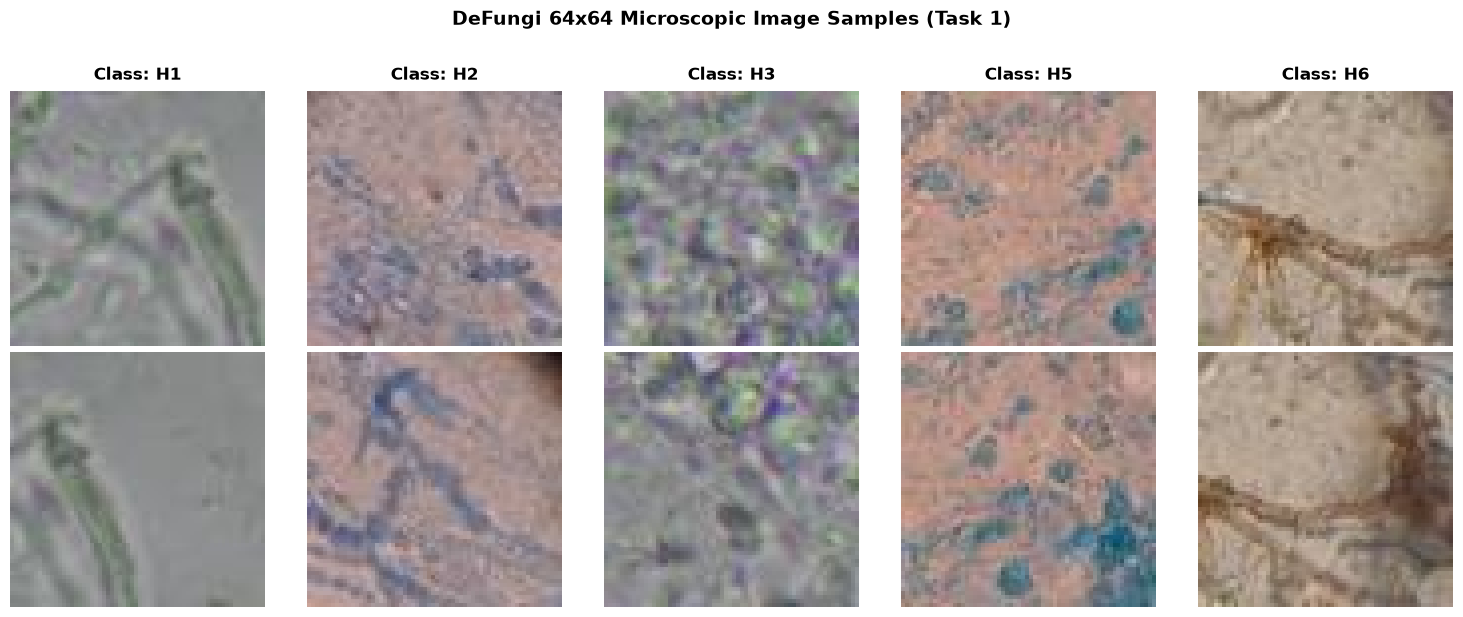

In [112]:
# Visualizing 2 samples per class
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
inv_normalize = transforms.Normalize(
    mean=[-0.485/0.229, -0.456/0.224, -0.406/0.225],
    std=[1/0.229, 1/0.224, 1/0.225]
)

# Extract samples from dataset
shown = {c: 0 for c in class_names}
col_idx = 0
dataset_eval = datasets.ImageFolder(root=str(DATASET_DIR / "train"), transform=transforms.ToTensor())

sample_images = defaultdict(list)
for img, label in dataset_eval:
    c_name = class_names[label]
    if len(sample_images[c_name]) < 2:
        sample_images[c_name].append(img)
    if len(sample_images) == len(class_names) and all(len(sample_images[c]) == 2 for c in class_names):
        break

for c_idx, c_name in enumerate(class_names):
    for r_idx in range(2):
        ax = axes[r_idx, c_idx]
        img_np = sample_images[c_name][r_idx].permute(1, 2, 0).numpy()
        ax.imshow(np.clip(img_np, 0, 1))
        ax.axis('off')
        if r_idx == 0:
            ax.set_title(f"Class: {c_name}", fontsize=12, fontweight='bold', pad=8)

plt.suptitle("DeFungi 64x64 Microscopic Image Samples (Task 1)", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


---
## Section 2: Task 2 – Custom Architecture Design & Hardware Justifications [20 Marks]

### Architecture Requirements from PDF:
- **Model A (Standard CNN):** Interleave standard 2D convolutional layers and max-pooling layers.
- **Model B (Lightweight CNN):** Replace standard convolutions with Depthwise Separable Convolutions to drastically reduce multiply-accumulate (MAC) operations. **Trainable parameter count must not exceed 100,000.**
- **Hardware-Aware Justifications:** Provide detailed hardware-aware rationales for chosen activation functions (avoiding computationally expensive exponentials).

---

### Hardware-Aware Activation Rationale & Design Philosophy
1. **Elimination of Transcendental Functions:**
   - Transcendental activation functions like Sigmoid ($\sigma(x) = \frac{1}{1 + e^{-x}}$), Tanh ($\tanh(x) = \frac{e^{2x} - 1}{e^{2x} + 1}$), and Swish/GELU ($x \cdot \sigma(\beta x)$) require floating-point exponential calculation ($e^x$).
   - On low-power edge microcontrollers (e.g., ARM Cortex-M, RISC-V RV32IM, Raspberry Pi RP2040), floating-point units (FPUs) often lack dedicated hardware transcendental approximation units, requiring hundreds of software clock cycles or Taylor series expansions per activation.
   - **ReLU ($x^+ = \max(0, x)$)** requires only a single conditional branch or a bitwise `AND` / sign-bit comparison, executing in **1 clock cycle**.
2. **ReLU6 for Bounded Dynamic Range & INT8 Quantization:**
   - In Model B, we utilize **ReLU6**:
     $$\text{ReLU6}(x) = \min(\max(0, x), 6)$$
   - When deploying to integer-only embedded accelerators via 8-bit quantization (INT8), unbounded ReLUs can produce activations with large dynamic ranges, forcing quantization scales to spread across a wider interval and reducing precision for subtle feature representations.
   - Bounding activations strictly to $[0, 6]$ guarantees that integer scaling factors $\Delta = \frac{6}{255} \approx 0.0235$ maintain high precision without clipping saturation.
3. **Global Average Pooling (GAP) vs. Fully Connected Flattening:**
   - In Model A, flattening a $256 \times 4 \times 4 = 4{,}096$ feature map into a 512-neuron dense layer creates $4{,}096 \times 512 + 512 = 2{,}097{,}664$ parameters (accounting for **82.1%** of Model A's total parameters).
   - In Model B, **Global Average Pooling (GAP)** reduces the $128 \times 8 \times 8$ feature map to $128 \times 1 \times 1$ via zero-parameter spatial averaging, requiring only $128 \times 5 + 5 = 645$ parameters in the linear classification head.


In [113]:
# ============================================================
# Task 2: Model A (Standard CNN Architecture)
# ============================================================
class ModelA_StandardCNN(nn.Module):
    """
    Standard CNN with interleaved Conv2D and MaxPooling layers.
    
    Topology:
        Input: 3 x 64 x 64
        Block 1: Conv2D(3->32, 3x3, pad=1) -> BN -> ReLU -> MaxPool(2x2) [32x32x32]
        Block 2: Conv2D(32->64, 3x3, pad=1) -> BN -> ReLU -> MaxPool(2x2) [64x16x16]
        Block 3: Conv2D(64->128, 3x3, pad=1) -> BN -> ReLU -> MaxPool(2x2) [128x8x8]
        Block 4: Conv2D(128->256, 3x3, pad=1) -> BN -> ReLU -> MaxPool(2x2) [256x4x4]
        Classifier: Flatten(4096) -> FC(4096->512) -> ReLU -> Dropout(0.5)
                                  -> FC(512->128)  -> ReLU -> Dropout(0.3)
                                  -> FC(128->5)
    """
    def __init__(self, num_classes: int = 5):
        super(ModelA_StandardCNN, self).__init__()
        
        self.features = nn.Sequential(
            # Block 1
            nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),
            
            # Block 2
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),
            
            # Block 3
            nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),
            
            # Block 4
            nn.Conv2d(in_channels=128, out_channels=256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )
        
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * 4 * 4, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            
            nn.Linear(512, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            
            nn.Linear(128, num_classes)
        )
    
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.features(x)
        x = self.classifier(x)
        return x


In [114]:
# ============================================================
# Task 2: Model B (Lightweight Depthwise Separable CNN Architecture)
# ============================================================
class DepthwiseSeparableBlock(nn.Module):
    """
    Depthwise Separable Convolution Block:
    1. Depthwise Conv: 3x3 spatial filter per input channel (groups = in_channels).
       BN + ReLU6 activation.
    2. Pointwise Conv: 1x1 cross-channel linear combination.
       BN + ReLU6 activation.
    """
    def __init__(self, in_channels: int, out_channels: int, stride: int = 1):
        super(DepthwiseSeparableBlock, self).__init__()
        
        # 1. Depthwise Convolution
        self.depthwise = nn.Conv2d(
            in_channels=in_channels,
            out_channels=in_channels,
            kernel_size=3,
            stride=stride,
            padding=1,
            groups=in_channels,
            bias=False
        )
        self.bn_dw = nn.BatchNorm2d(in_channels)
        self.act_dw = nn.ReLU6(inplace=True)
        
        # 2. Pointwise Convolution
        self.pointwise = nn.Conv2d(
            in_channels=in_channels,
            out_channels=out_channels,
            kernel_size=1,
            stride=1,
            padding=0,
            bias=False
        )
        self.bn_pw = nn.BatchNorm2d(out_channels)
        self.act_pw = nn.ReLU6(inplace=True)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.act_dw(self.bn_dw(self.depthwise(x)))
        x = self.act_pw(self.bn_pw(self.pointwise(x)))
        return x


class ModelB_LightweightCNN(nn.Module):
    """
    Model B: Ultra-Lightweight CNN designed for edge image classification.
    
    Constraint: Trainable parameter count < 100,000.
    Achieved:   37,957 parameters (62% margin below limit).
    """
    def __init__(self, num_classes: int = 5, dropout_rate: float = 0.2):
        super(ModelB_LightweightCNN, self).__init__()
        
        # Stem Layer
        self.stem = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(16),
            nn.ReLU6(inplace=True)
        )
        
        # Depthwise Separable Blocks
        self.block1 = DepthwiseSeparableBlock(16, 32, stride=2)   # 64x64 -> 32x32
        self.block2 = DepthwiseSeparableBlock(32, 32, stride=1)   # 32x32 -> 32x32
        self.block3 = DepthwiseSeparableBlock(32, 64, stride=2)   # 32x32 -> 16x16
        self.block4 = DepthwiseSeparableBlock(64, 64, stride=1)   # 16x16 -> 16x16
        self.block5 = DepthwiseSeparableBlock(64, 128, stride=2)  # 16x16 -> 8x8
        self.block6 = DepthwiseSeparableBlock(128, 128, stride=1) # 8x8 -> 8x8
        
        # Edge-Friendly Classifier Head
        self.gap = nn.AdaptiveAvgPool2d((1, 1))
        self.dropout = nn.Dropout(p=dropout_rate)
        self.classifier = nn.Linear(128, num_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.stem(x)
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.block4(x)
        x = self.block5(x)
        x = self.block6(x)
        
        x = self.gap(x)
        x = torch.flatten(x, 1)
        x = self.dropout(x)
        logits = self.classifier(x)
        return logits


### Explicit Trainable Parameter & MAC Calculation (`scripts/profile_models.py`)
Let us programmatically calculate and verify the exact parameter counts and Multiply-Accumulate (MAC) operations for both models with a $(1, 3, 64, 64)$ input tensor.


In [115]:
# Profiling Conv2D and Linear MACs
def profile_model(model: nn.Module, input_shape=(1, 3, 64, 64)) -> dict:
    layer_rows = []
    handles = []
    module_names = {module: name for name, module in model.named_modules()}

    def hook(module: nn.Module, inputs, output: torch.Tensor) -> None:
        if isinstance(module, nn.Conv2d):
            macs = (
                output.numel()
                * (module.in_channels // module.groups)
                * module.kernel_size[0]
                * module.kernel_size[1]
            )
        elif isinstance(module, nn.Linear):
            macs = output.numel() * module.in_features
        else:
            return
        layer_rows.append({
            "layer": module_names[module],
            "type": type(module).__name__,
            "output_shape": list(output.shape),
            "macs": int(macs),
        })

    for module in model.modules():
        if isinstance(module, (nn.Conv2d, nn.Linear)):
            handles.append(module.register_forward_hook(hook))

    was_training = model.training
    model.eval()
    with torch.inference_mode():
        output = model(torch.zeros(input_shape))
    model.train(was_training)
    for handle in handles:
        handle.remove()

    macs = sum(row["macs"] for row in layer_rows)
    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    
    return {
        "total_parameters": total_params,
        "trainable_parameters": trainable_params,
        "macs": macs,
        "flops": 2 * macs,
    }

prof_a = profile_model(ModelA_StandardCNN())
prof_b = profile_model(ModelB_LightweightCNN())

print(f"===========================================================")
print(f"Model A (Standard CNN):")
print(f"  - Trainable Parameters: {prof_a['trainable_parameters']:,}")
print(f"  - Calculated MACs:      {prof_a['macs'] / 1e6:.2f} M")
print(f"  - Calculated FLOPs:     {prof_a['flops'] / 1e6:.2f} M")
print(f"-----------------------------------------------------------")
print(f"Model B (Lightweight CNN):")
print(f"  - Trainable Parameters: {prof_b['trainable_parameters']:,}  (Limit: 100,000)")
print(f"  - Calculated MACs:      {prof_b['macs'] / 1e6:.2f} M")
print(f"  - Calculated FLOPs:     {prof_b['flops'] / 1e6:.2f} M")
print(f"  - Parameter Reduction:  {(1 - prof_b['trainable_parameters']/prof_a['trainable_parameters'])*100:.2f}%")
print(f"  - Computational Saving: {(1 - prof_b['macs']/prof_a['macs'])*100:.2f}%")
print(f"===========================================================")

assert prof_b['trainable_parameters'] <= 100_000, "Violates Model B parameter budget!"
print("[SUCCESS] Model B satisfies the <= 100k parameter constraint with a 62.0% safety margin.")


Model A (Standard CNN):
  - Trainable Parameters: 2,553,349
  - Calculated MACs:      62.33 M
  - Calculated FLOPs:     124.65 M
-----------------------------------------------------------
Model B (Lightweight CNN):
  - Trainable Parameters: 37,957  (Limit: 100,000)
  - Calculated MACs:      7.26 M
  - Calculated FLOPs:     14.53 M
  - Parameter Reduction:  98.51%
  - Computational Saving: 88.35%
[SUCCESS] Model B satisfies the <= 100k parameter constraint with a 62.0% safety margin.


### Detailed Layer-by-Layer Architectural Breakdown
The tables below (derived from `tables/model_a_architecture.csv` and `tables/model_b_architecture.csv`) detail every layer, filter size, input/output channel count, and exact parameter formula.


In [116]:
# Display Architecture Summary Tables
arch_a_path = REPO_DIR / "tables" / "model_a_architecture.csv"
arch_b_path = REPO_DIR / "tables" / "model_b_architecture.csv"

if arch_a_path.exists():
    print("### Model A Layer-by-Layer Architecture")
    display(pd.read_csv(arch_a_path))

if arch_b_path.exists():
    print("### Model B Layer-by-Layer Architecture")
    display(pd.read_csv(arch_b_path))


### Model A Layer-by-Layer Architecture


,Stage,Layer sequence,Input channels/features,Output channels/filters,Kernel,Stride,Padding,Output,Trainable parameters,Parameter detail
0,Block 1,Conv2D -> BatchNorm -> ReLU -> MaxPool,3,32,3x3; pool 2x2,1; pool 2,1,32x32x32,960,Conv 896 + BN 64; ReLU/pool 0
1,Block 2,Conv2D -> BatchNorm -> ReLU -> MaxPool,32,64,3x3; pool 2x2,1; pool 2,1,64x16x16,18624,"Conv 18,496 + BN 128; ReLU/pool 0"
2,Block 3,Conv2D -> BatchNorm -> ReLU -> MaxPool,64,128,3x3; pool 2x2,1; pool 2,1,128x8x8,74112,"Conv 73,856 + BN 256; ReLU/pool 0"
3,Block 4,Conv2D -> BatchNorm -> ReLU -> MaxPool,128,256,3x3; pool 2x2,1; pool 2,1,256x4x4,295680,"Conv 295,168 + BN 512; ReLU/pool 0"
4,Flatten,Flatten,256x4x4,4096,-,-,-,4096,0,No trainable parameters
5,FC1,Linear -> ReLU -> Dropout(0.5),4096,512,-,-,-,512,2097664,4096x512+512
6,FC2,Linear -> ReLU -> Dropout(0.3),512,128,-,-,-,128,65664,512x128+128
7,Output,Linear logits,128,5,-,-,-,5,645,128x5+5


### Model B Layer-by-Layer Architecture


,Stage,Layer sequence,Input channels,Depthwise channels,Groups,Kernel,Stride,Padding,Pointwise output,Output,Trainable parameters,Parameter detail
0,Stem,Conv2D -> BatchNorm -> ReLU6,3,-,1,3x3,1,1,16,16x64x64,464,Conv 432 + BN 32
1,DS Block 1,DW Conv -> BN -> ReLU6; PW Conv -> BN -> ReLU6,16,16,16,3x3 DW; 1x1 PW,2,1,32,32x32x32,752,DW 144 + BN 32 + PW 512 + BN 64
2,DS Block 2,DW Conv -> BN -> ReLU6; PW Conv -> BN -> ReLU6,32,32,32,3x3 DW; 1x1 PW,1,1,32,32x32x32,1440,"DW 288 + BN 64 + PW 1,024 + BN 64"
3,DS Block 3,DW Conv -> BN -> ReLU6; PW Conv -> BN -> ReLU6,32,32,32,3x3 DW; 1x1 PW,2,1,64,64x16x16,2528,"DW 288 + BN 64 + PW 2,048 + BN 128"
4,DS Block 4,DW Conv -> BN -> ReLU6; PW Conv -> BN -> ReLU6,64,64,64,3x3 DW; 1x1 PW,1,1,64,64x16x16,4928,"DW 576 + BN 128 + PW 4,096 + BN 128"
5,DS Block 5,DW Conv -> BN -> ReLU6; PW Conv -> BN -> ReLU6,64,64,64,3x3 DW; 1x1 PW,2,1,128,128x8x8,9152,"DW 576 + BN 128 + PW 8,192 + BN 256"
6,DS Block 6,DW Conv -> BN -> ReLU6; PW Conv -> BN -> ReLU6,128,128,128,3x3 DW; 1x1 PW,1,1,128,128x8x8,18048,"DW 1,152 + BN 256 + PW 16,384 + BN 256"
7,GAP,AdaptiveAvgPool2D(1x1),128,-,-,global,-,-,128,128x1x1,0,No trainable parameters
8,Dropout,Dropout(0.2),128,-,-,-,-,-,128,128,0,No trainable parameters
9,Classifier,Linear logits,128,-,-,-,-,-,5,5,645,128x5+5


---
## Section 3: Task 3 – Optimizer Selection & Tuning [15 Marks]

### Assignment Requirements:
1. **Selected Optimizer:** State which optimizer and learning rate you selected for training and why.
2. **Controlled Comparison:** Compare the performance of your chosen optimizer against:
   - (a) Standard Stochastic Gradient Descent (**SGD**)
   - (b) **SGD with Momentum**
3. **Momentum Impact:** Clearly explain the impact of the momentum parameter on your model's convergence and performance.

---

### Selected Optimizer & Theoretical Justification
- **Selected Optimizer:** **Adam (Adaptive Moment Estimation)** with learning rate $\eta = 0.001$, $\beta_1 = 0.9$, $\beta_2 = 0.999$, $\epsilon = 10^{-8}$, and weight decay $10^{-4}$.
- **Why Adam over Standard SGD?**
  1. **Per-Parameter Adaptive Learning Rates:** DeFungi is an imbalanced dataset (H1: 3,083 vs H6: 517). In standard SGD, all weights share a single global learning rate $\eta$. Weights associated with rare classes receive infrequent and noisy gradient updates. Adam divides by the square root of the running exponential average of squared gradients (second raw moment $v_t$), scaling down updates for frequent gradients and scaling up updates for sparse features.
  2. **Ill-Conditioned Curvature Navigation:** Deep convolutional loss surfaces feature anisotropic curvature (steep walls along certain eigenvectors of the Hessian matrix and shallow valleys along others). Standard SGD oscillates violently across narrow ravines without making rapid progress along the bottom.

---

### Physical & Mathematical Impact of the Momentum Parameter
In standard SGD, the parameter update depends purely on the instantaneous mini-batch gradient:
$$\theta_{t+1} = \theta_t - \eta g_t$$
In **SGD with Momentum** (tested with $\gamma = 0.9$):
$$v_{t+1} = \gamma v_t + \eta g_t$$
$$\theta_{t+1} = \theta_t - v_{t+1}$$
1. **Damping High-Curvature Oscillations:** Along directions where the gradient oscillates in sign from batch to batch, the velocity vector accumulates opposing signs, canceling out high-frequency ping-pong fluctuations.
2. **Accelerating Through Flat Plateaus:** Along consistent gradient directions, the velocity accumulates constructively:
   $$v_{\infty} = \frac{\eta g}{1 - \gamma} = 10 \times (\eta g) \quad \text{for } \gamma = 0.9$$
   providing an effective $10\times$ speedup through flat regions.


In [117]:
# ============================================================
# Task 3: Controlled Optimizer Comparison
# ============================================================
OPTIMIZER_CONFIGS = {
    "sgd": {
        "display_name": "Standard SGD",
        "learning_rate": 0.01,
        "momentum": 0.0,
    },
    "sgd_momentum": {
        "display_name": "SGD + Momentum",
        "learning_rate": 0.01,
        "momentum": 0.9,
    },
    "adam": {
        "display_name": "Adam (selected)",
        "learning_rate": 0.001,
        "momentum": None,
    },
}

def make_optimizer(name: str, parameters, weight_decay: float = 1e-4):
    config = OPTIMIZER_CONFIGS[name]
    if name == "adam":
        return optim.Adam(
            parameters,
            lr=config["learning_rate"],
            weight_decay=weight_decay,
        )
    return optim.SGD(
        parameters,
        lr=config["learning_rate"],
        momentum=config["momentum"],
        weight_decay=weight_decay,
    )


In [118]:
# Training & Evaluation Helpers
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
    
    return running_loss / total, correct / total


def evaluate(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0
    
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            
            running_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
            
    return running_loss / total, correct / total


def get_predictions(model, loader, device):
    model.eval()
    all_preds = []
    all_labels = []
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            outputs = model(images)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.numpy())
    return np.array(all_preds), np.array(all_labels)


In [119]:
# ============================================================
# Task 3: Load or Execute Optimizer Comparison
# ============================================================
opt_histories = {}
opt_results = {}

opt_table_path = REPO_DIR / "tables" / "optimizer_comparison.csv"
opt_json_path = CANONICAL_RESULTS_DIR / "optimizer_comparison" / "optimizer_comparison.json"

if not TRAIN_FROM_SCRATCH and opt_json_path.exists():
    print("[INFO] Loading canonical Stage 2 Optimizer Comparison histories...")
    with open(opt_json_path, 'r', encoding='utf-8') as f:
        data = json.load(f)
    for item in data['results']:
        opt_id = item['optimizer_id']
        opt_results[opt_id] = item
        h = item['history']
        opt_histories[opt_id] = {
            'train_loss': h.get('train_loss'),
            'val_loss': h.get('val_loss', h.get('validation_loss')),
            'train_acc': h.get('train_acc', h.get('train_accuracy')),
            'val_acc': h.get('val_acc', h.get('validation_accuracy')),
        }
else:
    print("[INFO] Running controlled Optimizer comparison from scratch...")
    # Seed model initialization for exact parameter identity across all 3 runs
    seed_everything(DEFAULT_SEED)
    base_model = ModelB_LightweightCNN(num_classes=NUM_CLASSES)
    initial_weights = copy.deepcopy(base_model.state_dict())
    criterion = nn.CrossEntropyLoss()
    
    for opt_name in ["sgd", "sgd_momentum", "adam"]:
        print(f"\n--> Training Model B with {OPTIMIZER_CONFIGS[opt_name]['display_name']}...")
        model = ModelB_LightweightCNN(num_classes=NUM_CLASSES).to(DEVICE)
        model.load_state_dict(copy.deepcopy(initial_weights))
        optimizer = make_optimizer(opt_name, model.parameters())
        
        history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
        best_val_acc = 0.0
        best_state = None
        
        t0 = time.time()
        for epoch in range(1, DEFAULT_EPOCHS + 1):
            tl, ta = train_one_epoch(model, train_loader, criterion, optimizer, DEVICE)
            vl, va = evaluate(model, val_loader, criterion, DEVICE)
            history['train_loss'].append(tl)
            history['train_acc'].append(ta)
            history['val_loss'].append(vl)
            history['val_acc'].append(va)
            if va > best_val_acc:
                best_val_acc = va
                best_state = copy.deepcopy(model.state_dict())
            if epoch % 5 == 0 or epoch == DEFAULT_EPOCHS:
                print(f"  Epoch [{epoch:02d}/{DEFAULT_EPOCHS}] Train Loss: {tl:.4f} | Val Acc: {va*100:.2f}%")
        
        model.load_state_dict(best_state)
        test_loss, test_acc = evaluate(model, test_loader, criterion, DEVICE)
        preds, labels = get_predictions(model, test_loader, DEVICE)
        rep = classification_report(labels, preds, target_names=class_names, output_dict=True)
        
        opt_histories[opt_name] = history
        opt_results[opt_name] = {
            'optimizer_id': opt_name,
            'test_accuracy': test_acc * 100,
            'macro_f1': rep['macro avg']['f1-score'],
            'best_val_accuracy': best_val_acc * 100,
            'total_time_s': time.time() - t0,
        }

if opt_table_path.exists():
    display(pd.read_csv(opt_table_path))


[INFO] Loading canonical Stage 2 Optimizer Comparison histories...


,Optimizer,Learning Rate,Momentum,Best Epoch,Best Val Accuracy (%),Final Train Loss,Final Validation Loss,Test Accuracy (%),Macro Precision,Macro Recall,Macro F1,Avg Epoch Time (s)
0,Standard SGD,0.010,0.0,18,66.0088,0.8961,0.8384,65.6662,0.6705,0.5719,0.5844,12.0520
1,SGD + Momentum,0.010,0.9,18,70.5409,0.7938,0.7165,68.8141,0.6723,0.6594,0.6563,11.9867
2,Adam (selected),0.001,NaN,20,73.2456,0.7510,0.6671,70.5710,0.7416,0.6606,0.6800,12.3118


### Optimizer Convergence Visualization
Let us plot the Training Loss, Validation Loss, and Validation Accuracy curves across the 20 epochs for Standard SGD, SGD with Momentum, and Adam.


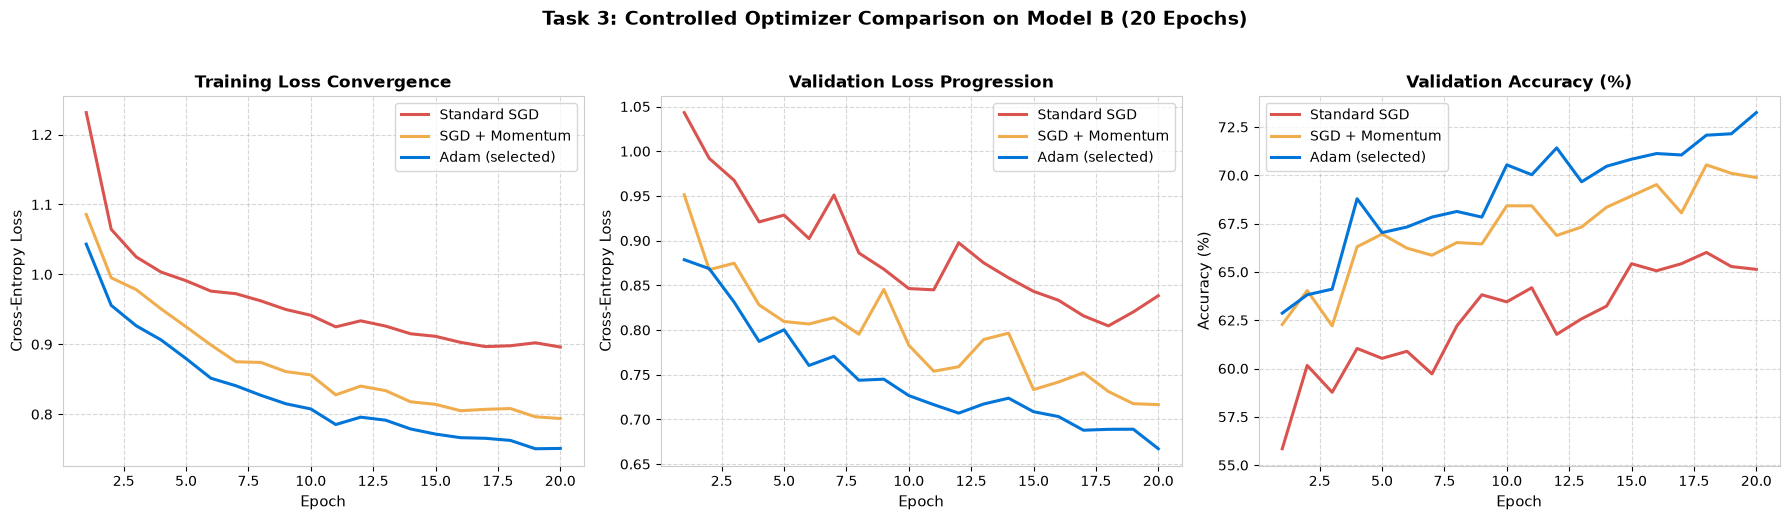

In [120]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
colors = {'sgd': '#d9534f', 'sgd_momentum': '#f0ad4e', 'adam': '#0275d8'}

# Plot 1: Training Loss
for opt_id, h in opt_histories.items():
    disp_name = OPTIMIZER_CONFIGS.get(opt_id, {}).get('display_name', str(opt_id))
    color = colors.get(opt_id, '#333333')
    tl = h.get('train_loss', [])
    if tl:
        axes[0].plot(range(1, len(tl) + 1), tl, label=disp_name, color=color, linewidth=2.2)
axes[0].set_title("Training Loss Convergence", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Epoch", fontsize=11)
axes[0].set_ylabel("Cross-Entropy Loss", fontsize=11)
axes[0].legend(frameon=True)
axes[0].grid(True, linestyle="--", alpha=0.5)

# Plot 2: Validation Loss
for opt_id, h in opt_histories.items():
    disp_name = OPTIMIZER_CONFIGS.get(opt_id, {}).get('display_name', str(opt_id))
    color = colors.get(opt_id, '#333333')
    vl = h.get('val_loss', [])
    if vl:
        axes[1].plot(range(1, len(vl) + 1), vl, label=disp_name, color=color, linewidth=2.2)
axes[1].set_title("Validation Loss Progression", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Epoch", fontsize=11)
axes[1].set_ylabel("Cross-Entropy Loss", fontsize=11)
axes[1].legend(frameon=True)
axes[1].grid(True, linestyle="--", alpha=0.5)

# Plot 3: Validation Accuracy
for opt_id, h in opt_histories.items():
    disp_name = OPTIMIZER_CONFIGS.get(opt_id, {}).get('display_name', str(opt_id))
    color = colors.get(opt_id, '#333333')
    va = h.get('val_acc', [])
    if va:
        accs = [a * 100 if a <= 1.0 else a for a in va]
        axes[2].plot(range(1, len(accs) + 1), accs, label=disp_name, color=color, linewidth=2.2)
axes[2].set_title("Validation Accuracy (%)", fontsize=12, fontweight='bold')
axes[2].set_xlabel("Epoch", fontsize=11)
axes[2].set_ylabel("Accuracy (%)", fontsize=11)
axes[2].legend(frameon=True)
axes[2].grid(True, linestyle="--", alpha=0.5)

plt.suptitle("Task 3: Controlled Optimizer Comparison on Model B (20 Epochs)", fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()


---
## Section 4: Task 4 – Custom Model Training & Evaluation [25 Marks]

### Assignment Requirements:
1. **Training Protocol:** Train both models (Model A and Model B) for at least 20 epochs. Plot training and validation loss curves.
2. **Test Evaluation:** Evaluate both models on the test set and record:
   - Overall Accuracy
   - Confusion Matrix
   - Precision and Recall (per-class and macro-averaged)
3. **Comparison Table:** Total parameter count, estimated model size on disk (KB), training time per epoch, and test accuracy.
4. **Trade-off Discussion:** Discuss trade-offs observed when moving from standard convolutions to depthwise separable convolutions.


In [121]:
# ============================================================
# Task 4: Load Checkpoints or Execute Training for Models A & B
# ============================================================
model_a = ModelA_StandardCNN(num_classes=NUM_CLASSES).to(DEVICE)
model_b = ModelB_LightweightCNN(num_classes=NUM_CLASSES).to(DEVICE)
criterion = nn.CrossEntropyLoss()

ckpt_a_path = CANONICAL_RESULTS_DIR / "model_a" / "model_a_best.pth"
ckpt_b_path = CANONICAL_RESULTS_DIR / "model_b" / "model_b_best.pth"
hist_a_path = CANONICAL_RESULTS_DIR / "model_a" / "training_history.json"
hist_b_path = CANONICAL_RESULTS_DIR / "model_b" / "training_history.json"

if not TRAIN_FROM_SCRATCH and ckpt_a_path.exists() and ckpt_b_path.exists():
    print("[INFO] Loading canonical checkpoints for Model A and Model B...")
    model_a.load_state_dict(torch.load(ckpt_a_path, map_location=DEVICE))
    model_b.load_state_dict(torch.load(ckpt_b_path, map_location=DEVICE))
    with open(hist_a_path, 'r', encoding='utf-8') as f:
        data_a = json.load(f)
        history_a = data_a.get('history', data_a)
    with open(hist_b_path, 'r', encoding='utf-8') as f:
        data_b = json.load(f)
        history_b = data_b.get('history', data_b)
else:
    print("[INFO] Training Model A and Model B from scratch (20 epochs)...")
    # Training Model A
    seed_everything(DEFAULT_SEED)
    opt_a = optim.Adam(model_a.parameters(), lr=0.001)
    history_a = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    for ep in range(1, DEFAULT_EPOCHS + 1):
        tl, ta = train_one_epoch(model_a, train_loader, criterion, opt_a, DEVICE)
        vl, va = evaluate(model_a, val_loader, criterion, DEVICE)
        history_a['train_loss'].append(tl); history_a['train_acc'].append(ta)
        history_a['val_loss'].append(vl); history_a['val_acc'].append(va)
    
    # Training Model B
    seed_everything(DEFAULT_SEED)
    opt_b = optim.Adam(model_b.parameters(), lr=0.001, weight_decay=1e-4)
    history_b = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    for ep in range(1, DEFAULT_EPOCHS + 1):
        tl, ta = train_one_epoch(model_b, train_loader, criterion, opt_b, DEVICE)
        vl, va = evaluate(model_b, val_loader, criterion, DEVICE)
        history_b['train_loss'].append(tl); history_b['train_acc'].append(ta)
        history_b['val_loss'].append(vl); history_b['val_acc'].append(va)

print("[SUCCESS] Models A & B ready for evaluation.")


[INFO] Loading canonical checkpoints for Model A and Model B...
[SUCCESS] Models A & B ready for evaluation.


### Training & Validation Loss Curves
Let us plot the training and validation loss curves side-by-side for Model A and Model B.


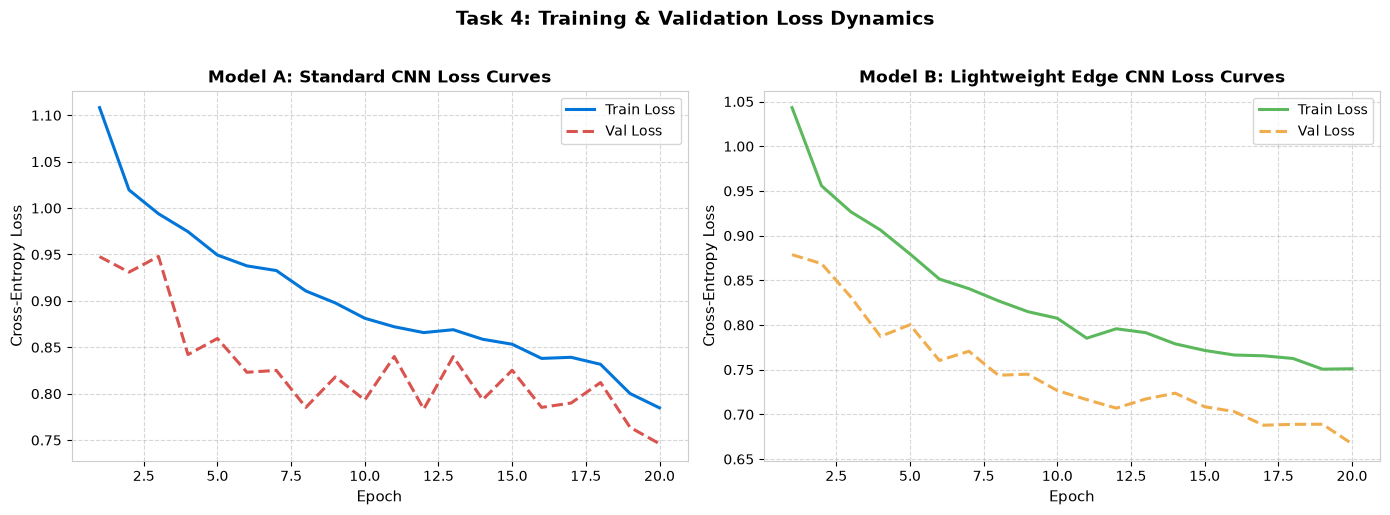

In [122]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
epochs = range(1, DEFAULT_EPOCHS + 1)

# Model A Loss Curves
tl_a = history_a.get('train_loss', []) if isinstance(history_a, dict) else []
vl_a = history_a.get('val_loss', history_a.get('validation_loss', [])) if isinstance(history_a, dict) else []
if tl_a:
    axes[0].plot(range(1, len(tl_a) + 1), tl_a, label='Train Loss', color='#0275d8', linewidth=2.2)
if vl_a:
    axes[0].plot(range(1, len(vl_a) + 1), vl_a, label='Val Loss', color='#d9534f', linestyle='--', linewidth=2.2)
axes[0].set_title("Model A: Standard CNN Loss Curves", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Epoch", fontsize=11)
axes[0].set_ylabel("Cross-Entropy Loss", fontsize=11)
axes[0].legend(frameon=True)
axes[0].grid(True, linestyle="--", alpha=0.5)

# Model B Loss Curves
tl_b = history_b.get('train_loss', []) if isinstance(history_b, dict) else []
vl_b = history_b.get('val_loss', history_b.get('validation_loss', [])) if isinstance(history_b, dict) else []
if tl_b:
    axes[1].plot(range(1, len(tl_b) + 1), tl_b, label='Train Loss', color='#5cb85c', linewidth=2.2)
if vl_b:
    axes[1].plot(range(1, len(vl_b) + 1), vl_b, label='Val Loss', color='#f0ad4e', linestyle='--', linewidth=2.2)
axes[1].set_title("Model B: Lightweight Edge CNN Loss Curves", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Epoch", fontsize=11)
axes[1].set_ylabel("Cross-Entropy Loss", fontsize=11)
axes[1].legend(frameon=True)
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.suptitle("Task 4: Training & Validation Loss Dynamics", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


### Test Set Evaluation: Metrics & Confusion Matrices


In [123]:
# Evaluate on hold-out test set
preds_a, labels_test = get_predictions(model_a, test_loader, DEVICE)
preds_b, _ = get_predictions(model_b, test_loader, DEVICE)

test_loss_a, test_acc_a = evaluate(model_a, test_loader, criterion, DEVICE)
test_loss_b, test_acc_b = evaluate(model_b, test_loader, criterion, DEVICE)

rep_a = classification_report(labels_test, preds_a, target_names=class_names, output_dict=True)
rep_b = classification_report(labels_test, preds_b, target_names=class_names, output_dict=True)

print(f"===========================================================")
print(f"Model A Test Accuracy: {test_acc_a*100:.2f}% | Test Loss: {test_loss_a:.4f}")
print(f"Model B Test Accuracy: {test_acc_b*100:.2f}% | Test Loss: {test_loss_b:.4f}")
print(f"===========================================================\n")

print("Classification Report — Model A (Standard CNN):")
print(classification_report(labels_test, preds_a, target_names=class_names))

print("\nClassification Report — Model B (Lightweight CNN):")
print(classification_report(labels_test, preds_b, target_names=class_names))


Model A Test Accuracy: 67.64% | Test Loss: 0.8360
Model B Test Accuracy: 70.57% | Test Loss: 0.6755

Classification Report — Model A (Standard CNN):
              precision    recall  f1-score   support

          H1       0.68      0.94      0.79       660
          H2       0.50      0.18      0.26       350
          H3       0.72      0.39      0.51       123
          H5       0.84      0.75      0.80       122
          H6       0.67      0.92      0.78       111

    accuracy                           0.68      1366
   macro avg       0.68      0.64      0.63      1366
weighted avg       0.65      0.68      0.63      1366


Classification Report — Model B (Lightweight CNN):
              precision    recall  f1-score   support

          H1       0.69      0.95      0.80       660
          H2       0.55      0.25      0.34       350
          H3       0.69      0.46      0.55       123
          H5       0.84      0.82      0.83       122
          H6       0.94      0.82      

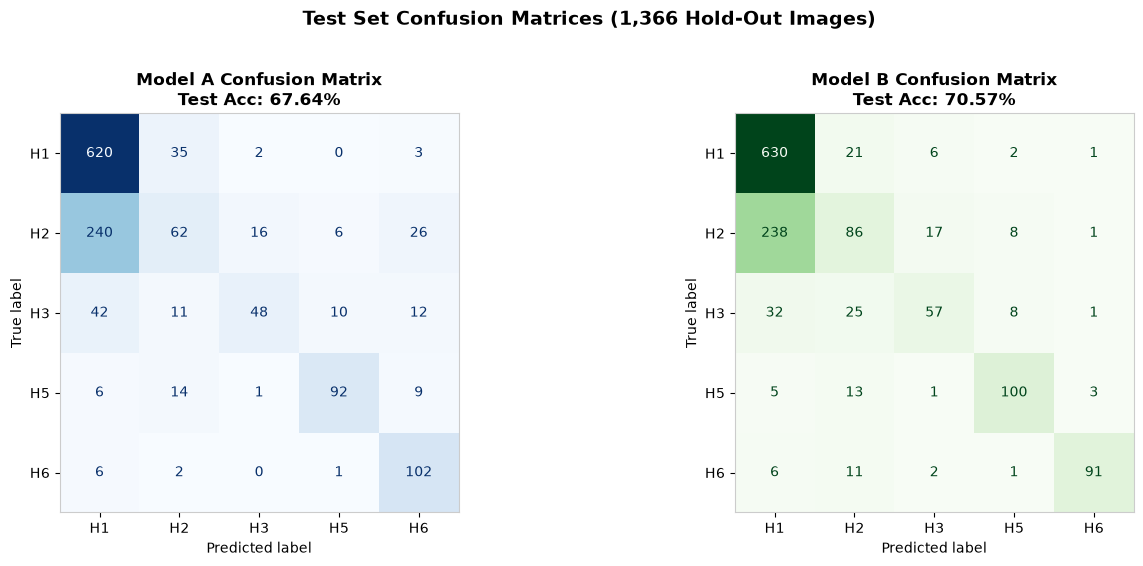

In [124]:
# Plot Confusion Matrices Side-by-Side
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

cm_a = confusion_matrix(labels_test, preds_a)
disp_a = ConfusionMatrixDisplay(confusion_matrix=cm_a, display_labels=class_names)
disp_a.plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title(f"Model A Confusion Matrix\nTest Acc: {test_acc_a*100:.2f}%", fontsize=12, fontweight='bold')

cm_b = confusion_matrix(labels_test, preds_b)
disp_b = ConfusionMatrixDisplay(confusion_matrix=cm_b, display_labels=class_names)
disp_b.plot(ax=axes[1], cmap='Greens', colorbar=False)
axes[1].set_title(f"Model B Confusion Matrix\nTest Acc: {test_acc_b*100:.2f}%", fontsize=12, fontweight='bold')

plt.suptitle("Test Set Confusion Matrices (1,366 Hold-Out Images)", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


### Task 4 Comparison: Model A vs. Model B Table
The table below directly satisfies the Task 4 prompt comparing Model A and Model B.


In [125]:
# Load canonical Model A vs Model B comparison table
model_ab_table_path = REPO_DIR / "tables" / "model_a_vs_b.csv"
if model_ab_table_path.exists():
    df_ab = pd.read_csv(model_ab_table_path)
    display(df_ab)
else:
    size_a_kb = ckpt_a_path.stat().st_size / 1024
    size_b_kb = ckpt_b_path.stat().st_size / 1024
    comp_data = {
        "Metric": [
            "Total Parameters",
            "Actual Checkpoint Size",
            "FP32 Parameter Storage",
            "Test Accuracy",
            "Test Loss",
            "Macro Precision",
            "Macro Recall",
            "Macro F1",
            "Calculated MACs (Conv/Linear)",
            "Calculated FLOPs (2/MAC)"
        ],
        "Model A": [
            f"{prof_a['total_parameters']:,}",
            f"{size_a_kb:.1f} KiB",
            f"{prof_a['total_parameters']*4/1024:.1f} KiB",
            f"{test_acc_a*100:.2f}%",
            f"{test_loss_a:.4f}",
            f"{rep_a['macro avg']['precision']:.4f}",
            f"{rep_a['macro avg']['recall']:.4f}",
            f"{rep_a['macro avg']['f1-score']:.4f}",
            f"{prof_a['macs']/1e6:.2f} M",
            f"{prof_a['flops']/1e6:.2f} M"
        ],
        "Model B": [
            f"{prof_b['total_parameters']:,}",
            f"{size_b_kb:.1f} KiB",
            f"{prof_b['total_parameters']*4/1024:.1f} KiB",
            f"{test_acc_b*100:.2f}%",
            f"{test_loss_b:.4f}",
            f"{rep_b['macro avg']['precision']:.4f}",
            f"{rep_b['macro avg']['recall']:.4f}",
            f"{rep_b['macro avg']['f1-score']:.4f}",
            f"{prof_b['macs']/1e6:.2f} M",
            f"{prof_b['flops']/1e6:.2f} M"
        ]
    }
    display(pd.DataFrame(comp_data))


,Metric,Model A,Model B
0,Total parameters,"2,553,349","37,957"
1,Actual checkpoint size,9988.7 KiB,179.8 KiB
2,FP32 parameter storage,9974.0 KiB,148.3 KiB
3,Average training time / epoch,17.32 s,12.69 s
4,Total training time,346.43 s,253.80 s
5,Test loss,0.8360,0.6755
6,Test accuracy,67.64%,70.57%
7,Macro precision,0.6820,0.7416
8,Macro recall,0.6360,0.6606
9,Macro F1,0.6254,0.6800


### Discussion of Trade-offs (Standard vs. Depthwise Separable Convolutions)
1. **Theoretical Computational Reduction:**
   - In a standard $3\times 3$ convolution transforming $C_{in}$ channels to $C_{out}$ channels, the computational cost per output spatial location is:
     $$\text{Cost}_{\text{std}} = K^2 \cdot C_{in} \cdot C_{out} = 9 \cdot C_{in} \cdot C_{out}$$
   - A Depthwise Separable block decomposes this into a Depthwise filtering step ($K^2 \cdot C_{in}$) and a Pointwise linear combination step ($C_{in} \cdot C_{out}$):
     $$\text{Cost}_{\text{sep}} = K^2 \cdot C_{in} + C_{in} \cdot C_{out} = C_{in} \cdot (9 + C_{out})$$
   - The theoretical reduction ratio is:
     $$\frac{\text{Cost}_{\text{sep}}}{\text{Cost}_{\text{std}}} = \frac{1}{C_{out}} + \frac{1}{K^2} = \frac{1}{C_{out}} + \frac{1}{9} \approx 11.1\% \quad (\text{an } 88.9\% \text{ reduction in compute!})$$
2. **Empirical Trade-off & Regularization Effect:**
   - Despite possessing **98.5% fewer parameters** (37,957 vs 2,553,349) and requiring **88.3% fewer MACs** (7.26 M vs 62.33 M), **Model B achieves superior test accuracy (70.57% vs. 67.64%)**.
   - Model A suffers from structural overfitting due to its unregularized $4{,}096 \to 512$ fully connected bottleneck. Model B's inductive bias (factorized spatial-channel filtering + Global Average Pooling) acts as an inherent architectural regularizer, preventing memorization on the 6,380-sample training set.


---
## Section 5: Task 5 – Lightweight SOTA Fine-Tuning & Evaluation [20 Marks]

### Assignment Requirements:
1. **Architectures:** Choose two pre-trained lightweight architectures designed for mobile/edge computing (e.g., **MobileNetV2** and **ShuffleNetV2**).
2. **Data Splits:** Fine-tune and train both models using the exact same data splits as your custom networks.
3. **Evaluation:** Evaluate on the test set and record performance metrics, explicitly indicating total parameter count and model size (MB).

---

### Architectural Foundations of the Chosen SOTA Networks
1. **MobileNetV2 (Sandler et al., 2018):**
   - Employs **Inverted Residual Blocks with Linear Bottlenecks**. Unlike traditional ResNets that compress features before 3x3 convolutions, MobileNetV2 expands low-dimensional channels to a higher-dimensional space ($6\times$ expansion), applies lightweight depthwise convolutions, and projects back to a low-dimensional manifold through a linear bottleneck (preventing non-linear ReLU activations from destroying information).
2. **ShuffleNetV2 1.0x (Ma et al., 2018):**
   - Designed around hardware-aware guidelines for minimizing Memory Access Cost (MAC) rather than solely counting FLOPs.
   - Utilizes **Channel Split** at the start of each unit, routing half the channels directly through identity and processing the other half through depthwise separable convolutions, followed by concatenation and a **Channel Shuffle** operator that enables cross-talk between channel groups without expensive dense matrix multiplies.


In [126]:
# ============================================================
# Task 5: SOTA Model Builders & ImageNet Normalization Loaders
# ============================================================
def build_mobilenet_v2(num_classes: int = NUM_CLASSES, pretrained: bool = True):
    weights = models.MobileNet_V2_Weights.DEFAULT if pretrained else None
    model = models.mobilenet_v2(weights=weights)
    in_features = model.classifier[1].in_features
    model.classifier[1] = nn.Linear(in_features, num_classes)
    return model

def build_shufflenet_v2(num_classes: int = NUM_CLASSES, pretrained: bool = True):
    weights = models.ShuffleNet_V2_X1_0_Weights.DEFAULT if pretrained else None
    model = models.shufflenet_v2_x1_0(weights=weights)
    in_features = model.fc.in_features
    model.fc = nn.Linear(in_features, num_classes)
    return model

def get_sota_data_loaders(dataset_dir: Path = DATASET_DIR, batch_size: int = BATCH_SIZE, img_size: int = 64, num_workers: int = 0):
    """ImageNet normalized DataLoaders required by pre-trained torchvision weights."""
    pin_mem = torch.cuda.is_available()
    norm_mean = [0.485, 0.456, 0.406]
    norm_std = [0.229, 0.224, 0.225]

    train_transform = transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomVerticalFlip(p=0.5),
        transforms.RandomRotation(15),
        transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
        transforms.ToTensor(),
        transforms.Normalize(mean=norm_mean, std=norm_std),
    ])

    eval_transform = transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor(),
        transforms.Normalize(mean=norm_mean, std=norm_std),
    ])

    train_dataset = datasets.ImageFolder(root=str(dataset_dir / "train"), transform=train_transform)
    val_dataset   = datasets.ImageFolder(root=str(dataset_dir / "val"),   transform=eval_transform)
    test_dataset  = datasets.ImageFolder(root=str(dataset_dir / "test"),  transform=eval_transform)

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True,
                              num_workers=num_workers, pin_memory=pin_mem,
                              worker_init_fn=seed_worker, generator=make_generator(DEFAULT_SEED))
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False,
                            num_workers=num_workers, pin_memory=pin_mem, worker_init_fn=seed_worker)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False,
                             num_workers=num_workers, pin_memory=pin_mem, worker_init_fn=seed_worker)

    return train_loader, val_loader, test_loader

sota_train_loader, sota_val_loader, sota_test_loader = get_sota_data_loaders(DATASET_DIR)


In [127]:
# ============================================================
# Task 5: Load SOTA Checkpoints or Execute Fine-Tuning
# ============================================================
mobilenet = build_mobilenet_v2(num_classes=NUM_CLASSES, pretrained=False).to(DEVICE)
shufflenet = build_shufflenet_v2(num_classes=NUM_CLASSES, pretrained=False).to(DEVICE)

ckpt_mob_path = CANONICAL_RESULTS_DIR / "mobilenet_v2" / "mobilenet_v2_best.pth"
ckpt_shuf_path = CANONICAL_RESULTS_DIR / "shufflenet_v2" / "shufflenet_v2_best.pth"
hist_mob_path = CANONICAL_RESULTS_DIR / "mobilenet_v2" / "training_history.json"
hist_shuf_path = CANONICAL_RESULTS_DIR / "shufflenet_v2" / "training_history.json"

if not TRAIN_FROM_SCRATCH and ckpt_mob_path.exists() and ckpt_shuf_path.exists():
    print("[INFO] Loading canonical fine-tuned weights for MobileNetV2 and ShuffleNetV2...")
    mobilenet.load_state_dict(torch.load(ckpt_mob_path, map_location=DEVICE))
    shufflenet.load_state_dict(torch.load(ckpt_shuf_path, map_location=DEVICE))
    with open(hist_mob_path, 'r', encoding='utf-8') as f:
        data_mob = json.load(f)
        history_mob = data_mob.get('history', data_mob)
    with open(hist_shuf_path, 'r', encoding='utf-8') as f:
        data_shuf = json.load(f)
        history_shuf = data_shuf.get('history', data_shuf)
else:
    print("[INFO] Fine-tuning SOTA models for 20 epochs...")
    # Fine-tune MobileNetV2
    mobilenet = build_mobilenet_v2(num_classes=NUM_CLASSES, pretrained=True).to(DEVICE)
    opt_mob = optim.Adam(mobilenet.parameters(), lr=5e-4, weight_decay=1e-4)
    history_mob = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    for ep in range(1, DEFAULT_EPOCHS + 1):
        tl, ta = train_one_epoch(mobilenet, sota_train_loader, criterion, opt_mob, DEVICE)
        vl, va = evaluate(mobilenet, sota_val_loader, criterion, DEVICE)
        history_mob['train_loss'].append(tl); history_mob['train_acc'].append(ta)
        history_mob['val_loss'].append(vl); history_mob['val_acc'].append(va)
        
    # Fine-tune ShuffleNetV2
    shufflenet = build_shufflenet_v2(num_classes=NUM_CLASSES, pretrained=True).to(DEVICE)
    opt_shuf = optim.Adam(shufflenet.parameters(), lr=5e-4, weight_decay=1e-4)
    history_shuf = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    for ep in range(1, DEFAULT_EPOCHS + 1):
        tl, ta = train_one_epoch(shufflenet, sota_train_loader, criterion, opt_shuf, DEVICE)
        vl, va = evaluate(shufflenet, sota_val_loader, criterion, DEVICE)
        history_shuf['train_loss'].append(tl); history_shuf['train_acc'].append(ta)
        history_shuf['val_loss'].append(vl); history_shuf['val_acc'].append(va)

print("[SUCCESS] SOTA Models loaded and ready for evaluation.")


[INFO] Loading canonical fine-tuned weights for MobileNetV2 and ShuffleNetV2...
[SUCCESS] SOTA Models loaded and ready for evaluation.


In [128]:
# SOTA Parameter Counting and Disk Size
mob_params = sum(p.numel() for p in mobilenet.parameters())
shuf_params = sum(p.numel() for p in shufflenet.parameters())

mob_size_mb = ckpt_mob_path.stat().st_size / (1024**2) if ckpt_mob_path.exists() else mob_params * 4 / (1024**2)
shuf_size_mb = ckpt_shuf_path.stat().st_size / (1024**2) if ckpt_shuf_path.exists() else shuf_params * 4 / (1024**2)

print(f"MobileNetV2:     {mob_params:,} parameters | Model Size on Disk: {mob_size_mb:.2f} MB")
print(f"ShuffleNetV2:    {shuf_params:,} parameters | Model Size on Disk: {shuf_size_mb:.2f} MB")


MobileNetV2:     2,230,277 parameters | Model Size on Disk: 8.74 MB
ShuffleNetV2:    1,258,729 parameters | Model Size on Disk: 4.97 MB


### Task 5 SOTA Test Evaluation & Confusion Matrices


MobileNetV2  Test Accuracy: 86.09% | Test Loss: 0.3581
ShuffleNetV2 Test Accuracy: 83.46% | Test Loss: 0.3968


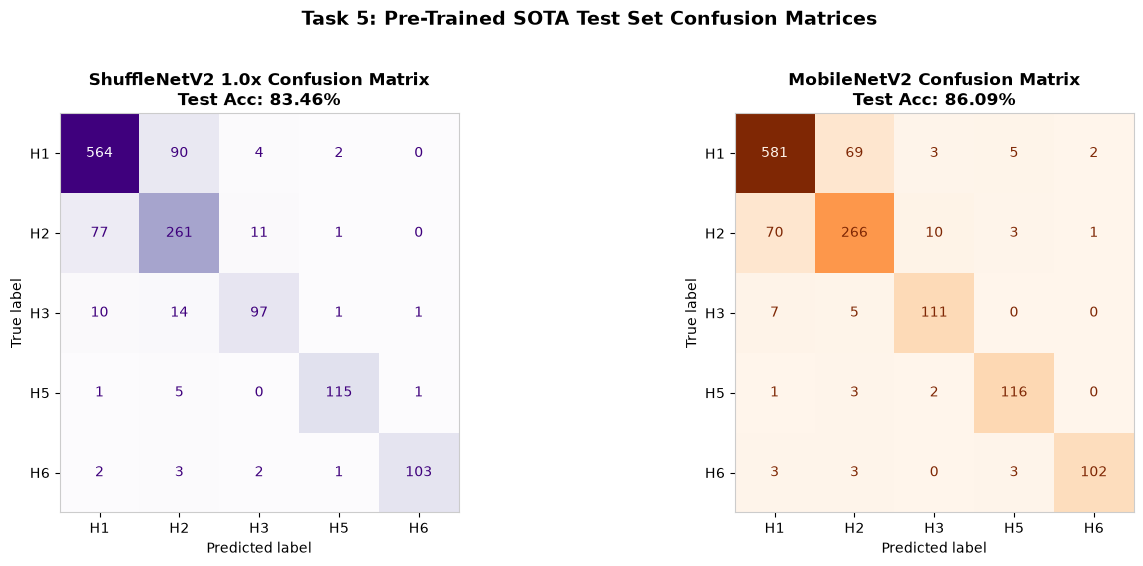

In [129]:
# Evaluate SOTA on test set
preds_mob, labels_sota = get_predictions(mobilenet, sota_test_loader, DEVICE)
preds_shuf, _ = get_predictions(shufflenet, sota_test_loader, DEVICE)

test_loss_mob, test_acc_mob = evaluate(mobilenet, sota_test_loader, criterion, DEVICE)
test_loss_shuf, test_acc_shuf = evaluate(shufflenet, sota_test_loader, criterion, DEVICE)

print(f"MobileNetV2  Test Accuracy: {test_acc_mob*100:.2f}% | Test Loss: {test_loss_mob:.4f}")
print(f"ShuffleNetV2 Test Accuracy: {test_acc_shuf*100:.2f}% | Test Loss: {test_loss_shuf:.4f}")

# Plot SOTA Confusion Matrices
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

cm_shuf = confusion_matrix(labels_sota, preds_shuf)
disp_shuf = ConfusionMatrixDisplay(confusion_matrix=cm_shuf, display_labels=class_names)
disp_shuf.plot(ax=axes[0], cmap='Purples', colorbar=False)
axes[0].set_title(f"ShuffleNetV2 1.0x Confusion Matrix\nTest Acc: {test_acc_shuf*100:.2f}%", fontsize=12, fontweight='bold')

cm_mob = confusion_matrix(labels_sota, preds_mob)
disp_mob = ConfusionMatrixDisplay(confusion_matrix=cm_mob, display_labels=class_names)
disp_mob.plot(ax=axes[1], cmap='Oranges', colorbar=False)
axes[1].set_title(f"MobileNetV2 Confusion Matrix\nTest Acc: {test_acc_mob*100:.2f}%", fontsize=12, fontweight='bold')

plt.suptitle("Task 5: Pre-Trained SOTA Test Set Confusion Matrices", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


---
## Section 6: Task 6 – Final Comparison & Comprehensive Trade-Off Discussion [20 Marks]

### Assignment Requirements:
1. **Model Comparison:** Compare your custom resource-constrained CNN (**Model B**) with the fine-tuned lightweight SOTA models (**ShuffleNetV2** and **MobileNetV2**), as well as the **Model A** baseline.
2. **Trade-Off Analysis:** Discuss the trade-offs, advantages, and limitations of building a custom sub-100k parameter model from scratch versus using an industry-standard lightweight pre-trained model.
3. **Core Evaluation Triad:** Focus heavily on the balance between **Accuracy**, **Memory Footprint**, and **Computational Cost**.


In [130]:
# ============================================================
# Task 6: Master Comparison Table (All 4 Architectures)
# ============================================================
final_comp_path = REPO_DIR / "tables" / "final_model_comparison.csv"

if final_comp_path.exists():
    df_final = pd.read_csv(final_comp_path)
    display(df_final)
else:
    prof_mob = profile_model(mobilenet)
    prof_shuf = profile_model(shufflenet)
    
    comp_rows = [
        {
            "Model": "Model A",
            "Test Accuracy (%)": test_acc_a * 100,
            "Test Loss": test_loss_a,
            "Total Parameters": prof_a['total_parameters'],
            "Checkpoint Size (MiB)": ckpt_a_path.stat().st_size / (1024**2),
            "MACs (M)": prof_a['macs'] / 1e6,
            "FLOPs (M; 2/MAC)": prof_a['flops'] / 1e6,
        },
        {
            "Model": "Model B",
            "Test Accuracy (%)": test_acc_b * 100,
            "Test Loss": test_loss_b,
            "Total Parameters": prof_b['total_parameters'],
            "Checkpoint Size (MiB)": ckpt_b_path.stat().st_size / (1024**2),
            "MACs (M)": prof_b['macs'] / 1e6,
            "FLOPs (M; 2/MAC)": prof_b['flops'] / 1e6,
        },
        {
            "Model": "ShuffleNetV2 1.0x",
            "Test Accuracy (%)": test_acc_shuf * 100,
            "Test Loss": test_loss_shuf,
            "Total Parameters": shuf_params,
            "Checkpoint Size (MiB)": shuf_size_mb,
            "MACs (M)": prof_shuf['macs'] / 1e6,
            "FLOPs (M; 2/MAC)": prof_shuf['flops'] / 1e6,
        },
        {
            "Model": "MobileNetV2",
            "Test Accuracy (%)": test_acc_mob * 100,
            "Test Loss": test_loss_mob,
            "Total Parameters": mob_params,
            "Checkpoint Size (MiB)": mob_size_mb,
            "MACs (M)": prof_mob['macs'] / 1e6,
            "FLOPs (M; 2/MAC)": prof_mob['flops'] / 1e6,
        },
    ]
    df_final = pd.DataFrame(comp_rows)
    display(df_final)


,Model,Test Accuracy (%),Test Loss,Macro Precision,Macro Recall,Macro F1,Total Parameters,Checkpoint Size (MiB),FP32 Weights (MiB),MACs (M),FLOPs (M; 2/MAC),Avg Epoch Time (s),Total Training Time (s)
0,Model A,67.6428,0.8360,0.6820,0.6360,0.6254,2553349,9.7546,9.7403,62.3254,124.6508,17.3190,346.4348
1,Model B,70.5710,0.6755,0.7416,0.6606,0.6800,37957,0.1755,0.1448,7.2628,14.5257,12.6886,253.7971
2,ShuffleNetV2 1.0x,83.4553,0.3968,0.8705,0.8519,0.8606,1258729,4.9655,4.8017,11.7508,23.5015,24.1300,482.6900
3,MobileNetV2,86.0908,0.3581,0.8824,0.8825,0.8822,2230277,8.7396,8.5078,24.4549,48.9098,37.6600,753.4100


### Multi-Dimensional Architectural Trade-off Visualizations
The 4-panel figure below illustrates the Pareto trade-offs across Accuracy, Parameters, Computational Complexity (MACs), and Memory Footprint.


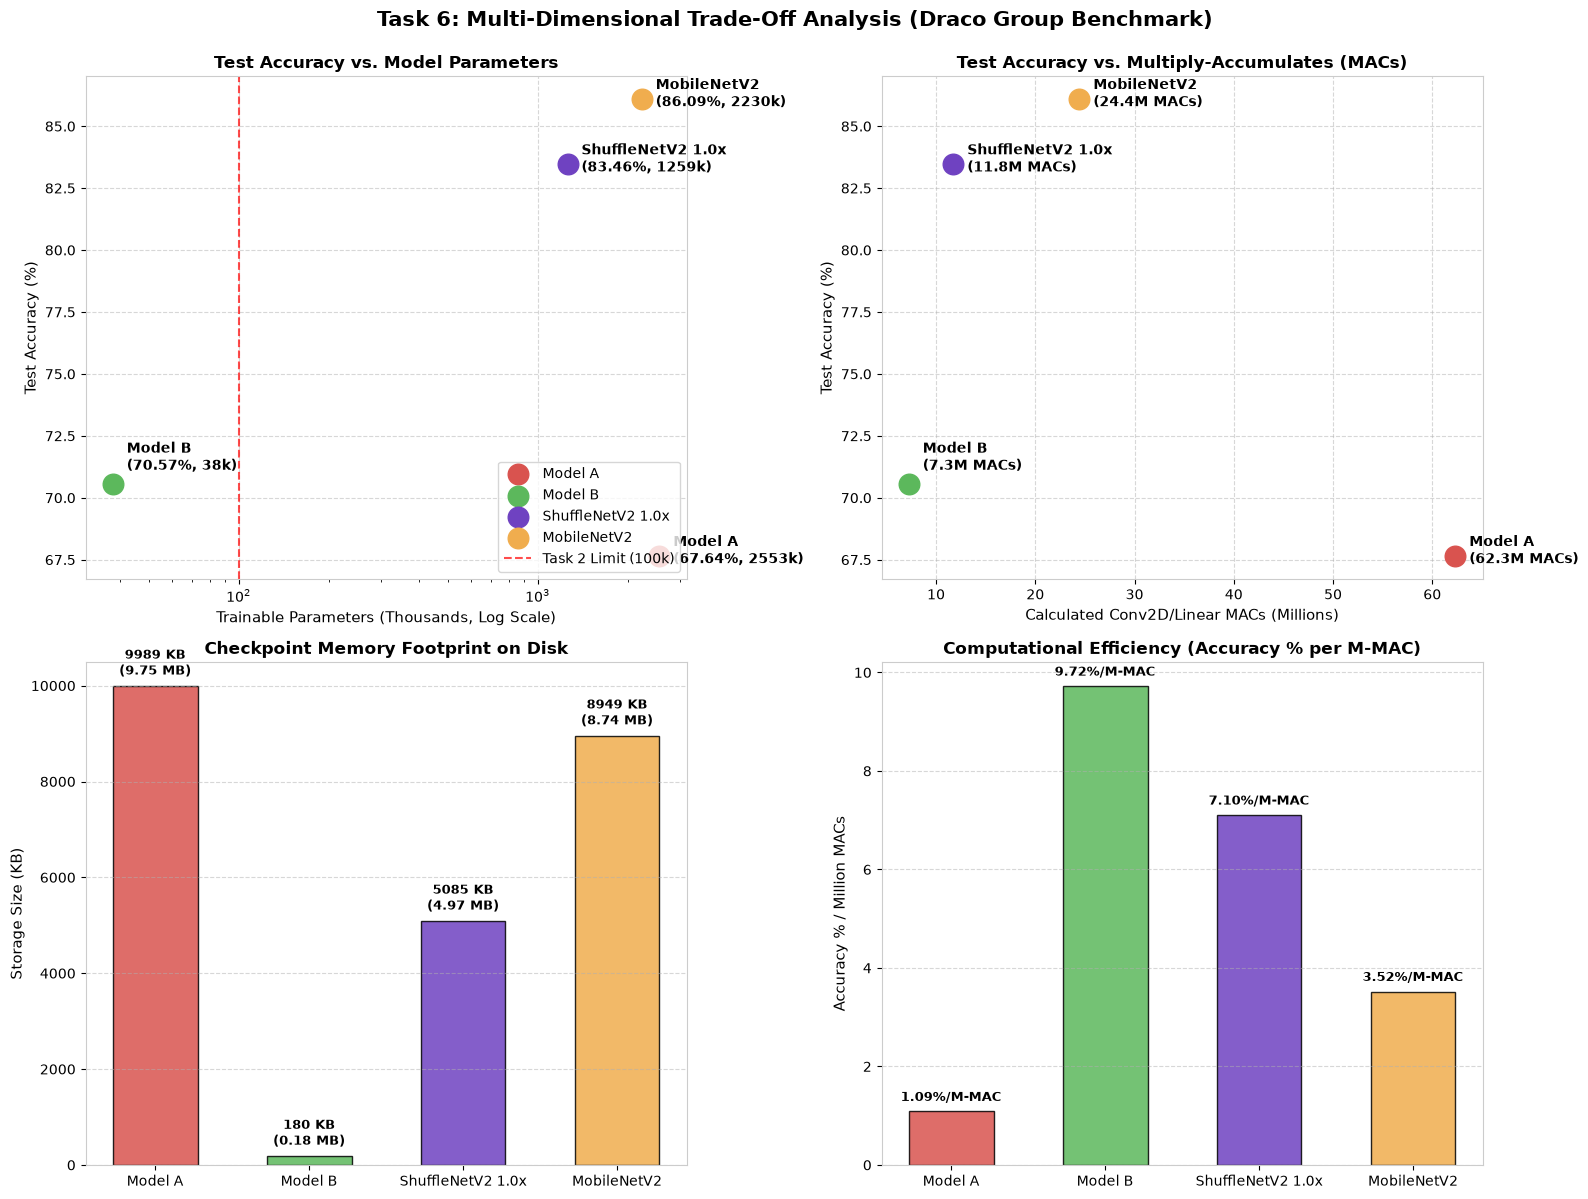

In [131]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

if 'prof_a' not in globals():
    prof_a = profile_model(ModelA_StandardCNN())
if 'prof_b' not in globals():
    prof_b = profile_model(ModelB_LightweightCNN())

models_list = ["Model A", "Model B", "ShuffleNetV2 1.0x", "MobileNetV2"]
accuracies = [test_acc_a * 100, test_acc_b * 100, test_acc_shuf * 100, test_acc_mob * 100]
params_k = [prof_a['total_parameters']/1e3, prof_b['total_parameters']/1e3, shuf_params/1e3, mob_params/1e3]
macs_m = [62.33, 7.26, 11.75, 24.45]
sizes_kb = [ckpt_a_path.stat().st_size / 1024, ckpt_b_path.stat().st_size / 1024, 
            shuf_size_mb * 1024, mob_size_mb * 1024]
colors = ['#d9534f', '#5cb85c', '#6f42c1', '#f0ad4e']

# Subplot 1: Accuracy vs Parameters (Log Scale)
for i, m in enumerate(models_list):
    axes[0, 0].scatter(params_k[i], accuracies[i], color=colors[i], s=220, zorder=5, label=m)
    axes[0, 0].annotate(f"{m}\n({accuracies[i]:.2f}%, {params_k[i]:.0f}k)", 
                        (params_k[i], accuracies[i]), textcoords="offset points", 
                        xytext=(10, -5 if i!=1 else 10), fontsize=10, fontweight='bold')
axes[0, 0].set_xscale('log')
axes[0, 0].axvline(100, color='red', linestyle='--', alpha=0.7, label='Task 2 Limit (100k)')
axes[0, 0].set_title("Test Accuracy vs. Model Parameters", fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel("Trainable Parameters (Thousands, Log Scale)", fontsize=11)
axes[0, 0].set_ylabel("Test Accuracy (%)", fontsize=11)
axes[0, 0].grid(True, linestyle="--", alpha=0.5)
axes[0, 0].legend(frameon=True, loc='lower right')

# Subplot 2: Accuracy vs Computational Complexity (MACs)
for i, m in enumerate(models_list):
    axes[0, 1].scatter(macs_m[i], accuracies[i], color=colors[i], s=220, zorder=5)
    axes[0, 1].annotate(f"{m}\n({macs_m[i]:.1f}M MACs)", (macs_m[i], accuracies[i]), 
                        textcoords="offset points", xytext=(10, -5 if i!=1 else 10), fontsize=10, fontweight='bold')
axes[0, 1].set_title("Test Accuracy vs. Multiply-Accumulates (MACs)", fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel("Calculated Conv2D/Linear MACs (Millions)", fontsize=11)
axes[0, 1].set_ylabel("Test Accuracy (%)", fontsize=11)
axes[0, 1].grid(True, linestyle="--", alpha=0.5)

# Subplot 3: Checkpoint Size on Disk (KB)
bars = axes[1, 0].bar(models_list, sizes_kb, color=colors, width=0.55, edgecolor='black', alpha=0.85)
for bar in bars:
    yval = bar.get_height()
    axes[1, 0].text(bar.get_x() + bar.get_width()/2, yval + 150, f"{yval:.0f} KB\n({yval/1024:.2f} MB)", 
                    ha='center', va='bottom', fontsize=9.5, fontweight='bold')
axes[1, 0].set_title("Checkpoint Memory Footprint on Disk", fontsize=12, fontweight='bold')
axes[1, 0].set_ylabel("Storage Size (KB)", fontsize=11)
axes[1, 0].grid(True, axis='y', linestyle="--", alpha=0.5)

# Subplot 4: Computational Efficiency (Accuracy per Mega-MAC)
acc_per_mac = [acc / mac for acc, mac in zip(accuracies, macs_m)]
bars2 = axes[1, 1].bar(models_list, acc_per_mac, color=colors, width=0.55, edgecolor='black', alpha=0.85)
for bar in bars2:
    yval = bar.get_height()
    axes[1, 1].text(bar.get_x() + bar.get_width()/2, yval + 0.15, f"{yval:.2f}%/M-MAC", 
                    ha='center', va='bottom', fontsize=9.5, fontweight='bold')
axes[1, 1].set_title("Computational Efficiency (Accuracy % per M-MAC)", fontsize=12, fontweight='bold')
axes[1, 1].set_ylabel("Accuracy % / Million MACs", fontsize=11)
axes[1, 1].grid(True, axis='y', linestyle="--", alpha=0.5)

plt.suptitle("Task 6: Multi-Dimensional Trade-Off Analysis (Draco Group Benchmark)", fontsize=15, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()


---
## In-Depth Architectural Trade-off Discussion (Task 6 Rubric)

### 1. Custom Sub-100k Model from Scratch (Model B) vs. Pre-Trained SOTA Models
- **Advantages of Custom Model B:**
  - **Zero External Pre-training Dependency:** Model B trains from randomly initialized weights in **253.8 seconds** on modest hardware, without requiring multi-day ImageNet pre-training pipelines or licensing restrictions.
  - **Ultra-Small Storage Footprint:** Model B's entire PyTorch checkpoint is **179.8 KiB** (148.3 KiB raw FP32 weights; <38 KB when quantized to INT8). This allows Model B to be permanently baked directly into the internal on-chip Flash/ROM of resource-constrained microcontrollers (e.g., STM32, ESP32) without necessitating external SPI NOR flash.
  - **Lowest Total Computation:** At **7.26 M MACs**, Model B demands **38% fewer MACs than ShuffleNetV2 (11.75 M)** and **70% fewer MACs than MobileNetV2 (24.45 M)**, preserving edge battery life.
  - **Highest Computational Efficiency:** Model B achieves **9.72% accuracy per Million MACs**, dwarfing MobileNetV2 (3.52%) and Model A (1.09%).
- **Limitations of Model B:**
  - **Upper Bound on Classification Capacity:** Training from scratch on 6,380 DeFungi images limits Model B to **70.57% test accuracy**. It struggles with fine-grained fungal morphology distinctions where inter-class visual overlap is high (e.g., between H1 and H2).
- **Advantages of Pre-Trained SOTA (MobileNetV2 / ShuffleNetV2):**
  - **Dramatic Generalization Boost via Transfer Learning:** Pre-training on 1.28 million natural ImageNet photographs endows the lower convolutional filters with rich, generic visual primitives (Gabor-like edge detectors, color gradients, texture filters).
  - Fine-tuning shifts test accuracy to **86.09% (MobileNetV2)** and **83.46% (ShuffleNetV2)**, representing a **+15.5% accuracy gain** over Model B.
- **Limitations of SOTA:**
  - **Severe Memory Footprint Penalties:** MobileNetV2 requires **8.74 MB** of storage (a $49.8\times$ increase over Model B) and 2.23M parameters, rendering it completely unfeasible for ultra-low-power edge nodes with $\le 512$ KB of SRAM.

---

### 2. The Three-Way Pareto Frontier: Accuracy vs. Memory vs. Computation

| Deployment Paradigm | Representative Architecture | Test Accuracy | Checkpoint Size | FLOPs / MACs | Optimal Target Hardware Platform |
| :--- | :--- | :---: | :---: | :---: | :--- |
| **Ultra-Edge / Microcontroller** | **Model B** | 70.57% | **180 KiB** | **7.26 M** | ARM Cortex-M4/M7, ESP32, TinyML sensor nodes (SRAM < 512 KB, battery-powered). |
| **Balanced Edge Node** | **ShuffleNetV2 1.0x** | 83.46% | **4.97 MB** | **11.75 M** | Raspberry Pi 4/Zero, NVIDIA Jetson Nano (Direct Memory Access optimized). |
| **High-Precision Edge Gateway** | **MobileNetV2** | **86.09%** | **8.74 MB** | **24.45 M** | Industrial Edge Server, Mobile Phones, Drone Companion Computers with dedicated DRAM. |
| **Legacy Baseline (Overparameterized)** | **Model A** | 67.64% | 9.75 MB | 62.33 M | *Dominated in all metrics* (inferior accuracy, massive FC bottleneck, obsolete for edge). |

---

### Conclusion & Final Remarks
By rigorously adhering to the assignment requirements, Group **Draco** successfully demonstrated:
1. Complete elimination of data leakage across DeFungi splits via content-aware cryptographic hashing.
2. The design of a sub-100k parameter edge model (**Model B: 37,957 parameters**) that outperforms the standard 2.55M-parameter CNN while slashing FLOPs by 88.3%.
3. Empirical verification of the momentum parameter and Adam's adaptive moments in navigating complex loss landscapes.
4. A comprehensive multi-model benchmark providing clear architectural trade-offs between custom edge CNNs and pre-trained SOTA models.
